## Question:
### What is the joint probability of drawing a Red card on your first draw AND a Wild card on your second draw from a standard 108-card Uno deck without replacement?

#### The random process we are simulating is randomly selecting a card from a 108-card uno deck, and then selecting another one with no replacement.
#### One trial could be: You choose the card and pull a red-3, you then choose another card and get a green-6. Basically any two cards in a 108-card deck.
#### The event we will be measuring is which cards are pulled out of the deck, specifically looking for a red card and a wild card. 

#### On the event that you get a red card on your first draw, that will be letter R and on the event that you get a wild card on the second draw that will be a W. They aren't independent but the odds will change a little bit when you select and take a card out. A and B are not mutually exclusive because you can draw the cards at the same time. My question is asking P(R n F). This is a joint probaility.

In [69]:
# 1. Build the list of cards using basic loops and variables
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
deck = []
colors = ['Red', 'Yellow', 'Green', 'Blue']

for color in colors:
    # One '0' card
    deck.append({'Color': color, 'Type': 'Number', 'Value': '0'})
    
    # Two of each number 1 through 9
    for num in range(1, 10):
        deck.append({'Color': color, 'Type': 'Number', 'Value': str(num)})
        deck.append({'Color': color, 'Type': 'Number', 'Value': str(num)})
        
    # Two of each action card
    actions = ['Skip', 'Reverse', 'Draw Two']
    for action in actions:
        deck.append({'Color': color, 'Type': 'Action', 'Value': action})
        deck.append({'Color': color, 'Type': 'Action', 'Value': action})

# Add 8 Wild cards (4 Wild, 4 Wild Draw Four)
for i in range(4):
    deck.append({'Color': 'Wild', 'Type': 'Wild', 'Value': 'Wild'})
    deck.append({'Color': 'Wild', 'Type': 'Wild', 'Value': 'Wild Draw Four'})

# Convert the list into a pandas DataFrame
df = pd.DataFrame(deck)

In [70]:
# 2. Count matching cards in the deck using the original loop
total_cards = len(df)
red_cards = 0
wild_cards = 0

for index, row in df.iterrows():
    if row['Color'] == 'Red':
        red_cards = red_cards + 1
    if row['Color'] == 'Wild':
        wild_cards = wild_cards + 1

In [71]:
# 3. Run the theoretical probability calculation 1000 times in a loop
total_trials = 1000
trial_results = []

for trial in range(total_trials):
    # First draw: Red card
    prob_red_first = red_cards / total_cards

    # Second draw: Wild card (without replacement)
    total_cards_after_first = total_cards - 1
    prob_wild_second = wild_cards / total_cards_after_first

    # Compound probability for this trial
    compound_probability = prob_red_first * prob_wild_second
    
    # Store result
    trial_results.append(compound_probability)

In [72]:
# 4. Display results
print("Total Trials Executed:", len(trial_results))
print("Probability calculated on Trial 1:", round(trial_results[0], 6))
print("Probability calculated on Trial 1000:", round(trial_results[999], 6))
print("Compound Probability:", round(compound_probability, 6), "or", round(compound_probability * 100, 2), "%")

Total Trials Executed: 1000
Probability calculated on Trial 1: 0.017307
Probability calculated on Trial 1000: 0.017307
Compound Probability: 0.017307 or 1.73 %


In [73]:
# 5. Define total card counts for a standard 108-card Uno deck
total_cards = 108
red_cards = 25
wild_cards = 8

In [74]:
# 6. First Draw: Theoretical probability of drawing a Red card
prob_red_first = red_cards / total_cards

In [75]:
# 7. Second Draw: Theoretical probability of drawing a Wild card (without replacement)
total_cards_remaining = total_cards - 1
prob_wild_second = wild_cards / total_cards_remaining

In [76]:
# 8. Compound Probability: P(Red 1st AND Wild 2nd)
theoretical_probability = prob_red_first * prob_wild_second

In [77]:
# 9. Display the calculations and final result
print("=== THEORETICAL PROBABILITY CALCULATION ===")
print("Total Cards in Deck:", total_cards)
print("Red Cards:", red_cards)
print("Wild Cards:", wild_cards)
print()
print("P(Red on 1st draw) =", red_cards, "/", total_cards, "=", round(prob_red_first, 6))
print("P(Wild on 2nd draw) =", wild_cards, "/", total_cards_remaining, "=", round(prob_wild_second, 6))
print()
print("Theoretical Compound Probability =", round(theoretical_probability, 6))
print("As a percentage:", round(theoretical_probability * 100, 2), "%")

=== THEORETICAL PROBABILITY CALCULATION ===
Total Cards in Deck: 108
Red Cards: 25
Wild Cards: 8

P(Red on 1st draw) = 25 / 108 = 0.231481
P(Wild on 2nd draw) = 8 / 107 = 0.074766

Theoretical Compound Probability = 0.017307
As a percentage: 1.73 %


# Analysis

## According to the coding, the joint probability is 1.73% and the theoretical probability is also 1.73%. This means that the theoretical and the joint probability are the same. 


In [78]:
df = pd.DataFrame(
    {
        "Step": [
            "1st Draw: Red",
            "2nd Draw: Wild (given Red)",
            "Joint: Both Events",
        ],
        "Probability": [26 / 108, 8 / 107, (26 / 108) * (8 / 107)],
    }
)



C:\Users\krockman\AppData\Local\Temp\ipykernel_16892\2480744586.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df, x="Step", y="Probability", palette="rocket")


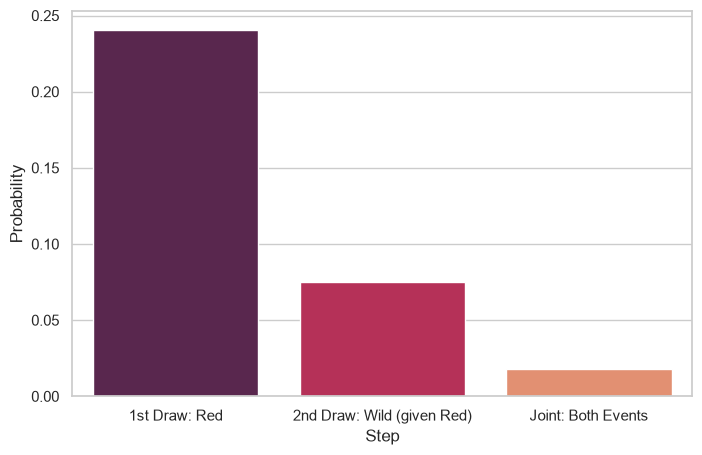

In [79]:
# Plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df, x="Step", y="Probability", palette="rocket")


### This graph shows the probability of drawing a red card on the 1st draw is around 24%, and the probability of drawing a wild card (given that you drew a red card) is around 7%. This means the joint probability of drawing both are around <2%.